RUN THIS FIRST BLOCK TO LAUNCH : FILTER WHEEL, LASER AND PICOSCOPE (MAKE SURE THEY ARE ALL DISCONNECTED FROM THEIR SOFTWARES)

In [1]:
import matplotlib.pyplot as plt
import os
import numpy as np
from datetime import datetime
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok
from ctypes import c_int16, c_int32, byref, c_char_p,c_float

#chrome-extension://efaidnbmnnnibpcajpcglclefindmkaj/https://www.picotech.com/download/manuals/picoscope-6000-series-programmers-guide.pdf

%load_ext autoreload
%autoreload 2

import Components as comp
import socket
import sys

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

components = dict()

filter_wheel = comp.FilterWheel(allowed_filter_positions=[0, 1, 2, 3, 4, 5])
laser = comp.Toptica_Laser()

def save_arrays(channel_data, time_array, stage_position, laser_power, base_directory='D:/Data'):
    """
    Saves voltage data from multiple channels and the corresponding time array.
    
    Parameters:
        channel_data (dict): Dictionary with channel names as keys and voltage data as values.
        time_array (np.ndarray): Time axis array.
        stage_position (str): Stage position for file naming.
        laser_power (str): Laser power for file naming.
        base_directory (str): Base directory for saving data."""
    # Get current year, year+month, and year+month+day in the desired format
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')
    # Define the folder path following the structure Year/YearMonth/YearMonthDay
    folder_path = os.path.join(base_directory, year, year_month, year_month_day)
    # Create the directory structure if it doesn't exist
    os.makedirs(folder_path, exist_ok=True)
    # Create timestamp for file naming
    timestamp = datetime.now().strftime('%H%M%S')  # Using HHMMSS format for timestamp
    # Save each channel's data with a distinctive file name
    for channel, voltage_array in channel_data.items():
        # Generate filename for the channel data
        filename_voltage = f"pbec_{timestamp}_{stage_position}_{laser_power}_channel{channel}.txt"
        # Define full path
        array_path_voltage = os.path.join(folder_path, filename_voltage)
        # Save voltage data for this channel
        np.savetxt(array_path_voltage, voltage_array, fmt='%0.4f')
    # Save the time array with a distinctive name
    filename_time = f"pbec_{timestamp}_{stage_position}_{laser_power}_Time.txt"
    time_path = os.path.join(folder_path, filename_time)
    np.savetxt(time_path, time_array, fmt='%0.4f')


def get_picoscope_data(
        channels=[0],  # List of channels to acquire from, e.g., [0, 1] for channels A and B
        analogue_offset=0,
        trig=0,
        trigsource=0,
        trigthresh=64,
        trigdir=2,
        trigdelay=0,
        trigms=1000,
        preTriggerSamples=2500,
        postTriggerSamples=2500,
        timebase=8,
        live_plot=False
):
    # Initialize PicoScope
    status = {}
    chandle = c_int16()
    serial = c_char_p()  # Leave serial empty for single device
    status["openunit"] = ps.ps6000OpenUnit(byref(chandle), serial)
    assert status["openunit"] == 0, f"Failed to open PicoScope 6407, error code: {status['openunit']}"
    # Channel configuration mapping
    channel_mapping = {
        0: 'PS6000_CHANNEL_A',
        1: 'PS6000_CHANNEL_B',
        2: 'PS6000_CHANNEL_C',
        3: 'PS6000_CHANNEL_D'
    }
    # Enable and configure each specified channel
    buffers = {}
    chARange = ps.PS6000_RANGE['PS6000_100MV']  # ±100 mV range, the only range available for PicoScope 6407
    for ch in channels:
        if ch not in channel_mapping:
            raise ValueError("Invalid channel number. Must be 0, 1, 2, or 3.")
        channel = ps.PS6000_CHANNEL[channel_mapping[ch]]
        enabled = 1  # 1 for enabling
        coupling_type = ps.PS6000_COUPLING['PS6000_DC_50R']  # Only DC 50Ω coupling for PicoScope 6407
        bandwidth = ps.PS6000_BANDWIDTH_LIMITER['PS6000_BW_FULL']  # Full bandwidth
        # Set channel
        status[f"set_channel_{ch}"] = ps.ps6000SetChannel(
            chandle, channel, enabled, coupling_type, chARange, analogue_offset, bandwidth
        )
        assert status[f"set_channel_{ch}"] == 0, f"Error in setting channel {ch}: {status[f'set_channel_{ch}']}"
        # Create buffers for data collection on each channel
        buffers[ch] = {
            'max': (c_int16 * (preTriggerSamples + postTriggerSamples))(),
            'min': (c_int16 * (preTriggerSamples + postTriggerSamples))()  # Used for downsampling
        }
        # Set data buffer location for data collection
        status[f"setDataBuffers_{ch}"] = ps.ps6000SetDataBuffers(
            chandle, channel, byref(buffers[ch]['max']), byref(buffers[ch]['min']), preTriggerSamples + postTriggerSamples, 0
        )
        assert_pico_ok(status[f"setDataBuffers_{ch}"])
    # Trigger setup
    status["trigger"] = ps.ps6000SetSimpleTrigger(
        chandle, trig, trigsource, trigthresh, trigdir, trigdelay, trigms
    )
    assert_pico_ok(status["trigger"])
    # Set number of pre and post trigger samples
    maxSamples = preTriggerSamples + postTriggerSamples
    # Get timebase information
    timeIntervalns = c_float()
    returnedMaxSamples = c_int32()
    status["getTimebase2"] = ps.ps6000GetTimebase2(
        chandle, timebase, maxSamples, byref(timeIntervalns), 1, byref(returnedMaxSamples), 0
    )
    assert_pico_ok(status["getTimebase2"])
    # Run block capture
    status["runBlock"] = ps.ps6000RunBlock(
        chandle, preTriggerSamples, postTriggerSamples, timebase, 0, None, 0, None, None
    )
    assert_pico_ok(status["runBlock"])
    # Wait for data collection to complete
    ready = c_int16(0)
    while ready.value == 0:
        status["isReady"] = ps.ps6000IsReady(chandle, byref(ready))
    # Retrieve data from scope to buffers for each channel
    overflow = c_int16()
    cmaxSamples = c_int32(maxSamples)
    status["getValues"] = ps.ps6000GetValues(
        chandle, 0, byref(cmaxSamples), 1, 0, 0, byref(overflow)
    )
    assert_pico_ok(status["getValues"])
    # Find maximum ADC count value
    maxADC = c_int16(32512)
    # Convert data from each channel buffer to mV and store in a dictionary
    channel_data = {}
    for ch in channels:
        adc2mV_buffer = adc2mV(buffers[ch]['max'], chARange, maxADC)
        channel_data[ch] = adc2mV_buffer
    time = np.linspace(0, (cmaxSamples.value - 1) * timeIntervalns.value, cmaxSamples.value) # Create time data
    # Plot data from each channel if live_plot is enabled
    if live_plot:
        plt.figure(figsize=(5,5))
        for ch in channels:
            plt.plot(time, channel_data[ch][:], label=f"Channel {channel_mapping[ch]}")
        plt.xlabel('Time (ns)')
        plt.ylabel('Voltage (mV)')
        plt.title("PicoScope Data Capture on Multiple Channels")
        plt.legend()
        plt.grid()
        plt.show()
    # Stop the device
    status["stop"] = ps.ps6000Stop(chandle)
    assert_pico_ok(status["stop"])
    ps.ps6000CloseUnit(chandle) # Close unit (disconnect the scope)
    return channel_data, time # Return channel data and time for further processing

THIS CODE IS FOR MULTICHANNEL PICOSCOPE COHERENCE ACQUISITION (MAKE SURE TO CHANGE PARAMETERS AND FILTER POSITIONS BEFORE SCANNING)

In [1]:
%load_ext autoreload
%autoreload 2
import heapq
import time

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")

#_________________________________________________________PARAMETERS : CHANGE HERE____________________________________________________________
position_list = np.append(np.append(np.arange(0,50,5),np.arange(50,300,10)),np.arange(300,630,30))
power_list = np.append(np.append(np.append([0],np.arange(17,40,1)/1000),np.arange(40,70,5)/1000),np.arange(70,120,10)/1000)
channels = [0, 1]  # Channel A, B
number_of_measurements = 1 # Amount of pics to take at each position of the stage
time_range = 1000
preSamples = 0
postSamples = 300000
plot_flag = False # If you want to live monitor the data during the acquisition
n_avg = 50 # Number of points over which to perform averaging for Imax and Imin
DC = 3.97
filter_positions = { # Preset the filter position for each power value - Need to be done manually, do it everytime before taking measurements
    18:0,
    23:1,
    30:2,
    48:3,
    84:4,
    # Add more power settings as needed
}
#_________________________________________________________________________________________________________________________________

with comp.Translation_Stage() as stage:
    for power in power_list:
        laser.set(power)
        print('Starting scan for power : ', power*1000)
        stage.set(position_list[0])
        visibilities = []
        time.sleep(5)
        try:
            
            if power*1000 in filter_positions:
                    filter_position = filter_positions[power*1000]
                    filter_wheel.set(filter_position)  # Set the filter position accordingly
                    print(f'Filter position set to: {filter_position+1} for power {power*1000}')
            real_positions =[]
            for k in range(len(position_list)):
                stage.set(position_list[k])
                position = stage.get_position()
                real_positions.append(position)
                
                for k in range(number_of_measurements):
                    a = get_picoscope_data(channels,live_plot=plot_flag,timebase = time_range, preTriggerSamples=preSamples,postTriggerSamples=postSamples)
                    Voltages = a[0]
                    Timing = a[1]
                    chA = np.abs(np.array(a[0][0]))
                    chB = np.abs(np.array(a[0][1]))
                    bg = np.abs(min(chB))+2.15
                    chC = (chA-DC)/(chB+bg)
                    highest_vals = heapq.nlargest(n_avg, chC)
                    lowest_vals = heapq.nsmallest(n_avg, chC)
                    Imax = np.mean(highest_vals)
                    Imin = np.mean(lowest_vals)
                    visibility = (Imax-Imin)/(Imax+Imin)
                    visibilities.append(visibility)
                    save_arrays(Voltages, Timing, position,power*1000)
                    print('Now at Position : ', position, ' / Visibility : ', visibility)
                time.sleep(1)
            plt.plot(real_positions,visibilities,'o')
            plt.xlabel('stage position')
            plt.ylabel('visibilities')
            plt.show()
            print(real_positions,visibilities)
        except:
            print('An exception occured')
        
    laser.set(0)

NameError: name 'socket' is not defined

FILTER POSITIONS CALIBRATION, TEST

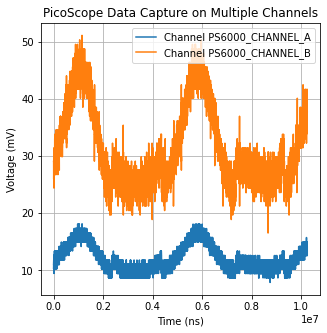

Time resolution is :  51.20000076293945 ns
Integration time is :  10239948.952587128 ns
12.155724409448817
31.443330708661424
Visibility is :  0.3150136708136598


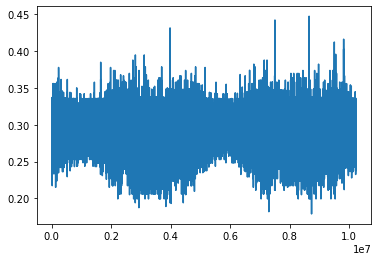

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import heapq
import socket
import sys


channels = [0, 1]
timebase = 12
postTriggerSamples = 200000
DCA = 3.71
DCB = 1.94
laser_power =14
n_avg = 100




laser.set(laser_power/1000)
a = get_picoscope_data(channels,live_plot=True,timebase = timebase, preTriggerSamples=0,postTriggerSamples=postTriggerSamples)
voltageA = np.abs(np.array(a[0][0]))
voltageB = np.abs(np.array(a[0][1]))
time = a[1]
voltageC = (voltageA-DCA)/(voltageB-DCB)
highest_n = heapq.nlargest(n_avg, voltageC)
lowest_n = heapq.nsmallest(n_avg, voltageC)
Imax = np.mean(highest_n)
Imin = np.mean(lowest_n)

print('Time resolution is : ',time[1], 'ns')
print('Integration time is : ', time[-1], 'ns')
print(np.mean(voltageA))
print(np.mean(voltageB))
#plt.hist(voltageC,bins=100)
plt.plot(time,voltageC)
print("Visibility is : ",(Imax-Imin)/(Imax+Imin))
plt.xlim()
plt.show()


ONE MIRROR INTENSITY SCAN

Time resolution is :  51.20000076293945 ns
Integration time is :  10239948.952587128 ns
Standard deviation :  0.006079473661428271
Mean :  0.6048


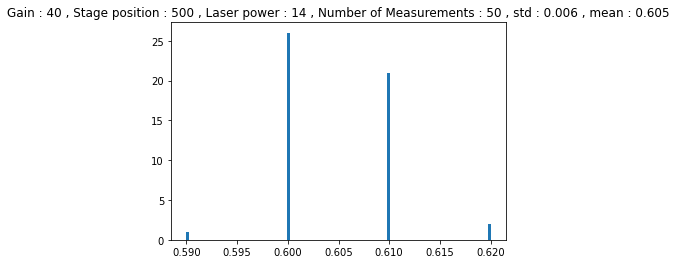

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import heapq
import socket
import sys


channels = [0, 1]
timebase = 12
postTriggerSamples = 200000

laser_power = 14
n_avg = 250
n_run = 50
G = 40
sp = 500
DCs = {
    30: [3.57,1.85],
    40:[3.71,1.94],
    50:[3.86,1.93],
    60:[4.17,1.86],
}

DCA = DCs[G][0]
DCB = DCs[G][1]

laser.set(laser_power/1000)
visibilities = []
for k in range(n_run):
    a = get_picoscope_data(channels,live_plot=False,timebase = timebase, preTriggerSamples=0,postTriggerSamples=postTriggerSamples)
    voltageA = np.abs(np.array(a[0][0]))
    voltageB = np.abs(np.array(a[0][1]))
    time = a[1]
    voltageC = (voltageA-DCA)/(voltageB-DCB)
    highest_n = heapq.nlargest(n_avg, voltageC)
    lowest_n = heapq.nsmallest(n_avg, voltageC)
    Imax = np.mean(highest_n)
    Imin = np.mean(lowest_n)
    visibility = (Imax-Imin)/(Imax+Imin)
    visibilities.append(round(visibility,2))
print('Time resolution is : ',time[1], 'ns')
print('Integration time is : ', time[-1], 'ns')
plt.hist(visibilities,bins=100)
plt.title(f'Gain : {G} , Stage position : {sp} , Laser power : {laser_power} , Number of Measurements : {n_run} , std : {round(np.std(visibilities),3)} , mean : {round(np.mean(visibilities),3)}')
print("Standard deviation : ",np.std(visibilities))
print("Mean : ",np.mean(visibilities))

plt.show()

In [ ]:
%load_ext autoreload
%autoreload 2

import time

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")

#_________________________________________________________CHANGE HERE____________________________________________________________
position_list = np.arange(214,114,-10)
# power_list = np.append(np.append(np.arange(56,70,0.5)/1000,np.arange(70,100,5)/1000),np.arange(100,150,10)/1000) #CHANGE HERE
#power_list = np.array([25.2])/1000
power_list = np.append(np.append(np.arange(26,50,0.5)/1000,np.arange(50,70,1)/1000),np.arange(70,100,2)/1000)
number_of_measurements = 1 # Amount of pics to take at each position of the stage
time_range = 1000
preSamples = 0
postSamples = 100000
plot_flag = False
#_________________________________________________________________________________________________________________________________

filter_positions = { # Preset the filter position for each power value - Need to be done manually, do it everytime before taking measurements
    35: 0,
    40: 1,
    50: 2,
    60: 3,
    90: 4, 
    # Add more power settings as needed
}
position = 0

for power in power_list:
    laser.set(power)
    print('Starting scan for power : ', power*1000)
    
    try:
        
        if power*1000 in filter_positions:
                filter_position = filter_positions[power*1000]
                filter_wheel.set(filter_position)  # Set the filter position accordingly
                print(f'Filter position set to: {filter_position+1} for power {power*1000}')
            
        for k in range(number_of_measurements):
            a = get_picoscope_data(0,live_plot=plot_flag,timebase = time_range, preTriggerSamples=preSamples,postTriggerSamples=postSamples)
            Voltage = a[0]
            Timing = a[1]
            save_arrays(Voltage, Timing, position,power*1000)
        time.sleep(2)
    except:
        print('An exception occured')
    
laser.set(0)

In [115]:
G = 50

DCs = {
    30: [3.57,1.85],
    40:[3.71,1.94],
    50:[3.86,1.93],
    60:[4.17,1.86],
}

DCA = DCs[G][0]
DCB = DCs[G][1]

print(DCA,DCB)

3.86 1.93


In [ ]:
np.arange(150,630,30)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


c:\users\photonbec\appdata\local\programs\python\python38-32\lib\site-packages\pylablib\devices\Thorlabs\kinesis.py:230: UserWarning: model number BBD201 doesn't match the device ID prefix 73(BBD103)
  warnings.warn("model number {} doesn't match the device ID prefix {}({})".format(model_no,port,port_model_no))


Starting scan for power :  10.0


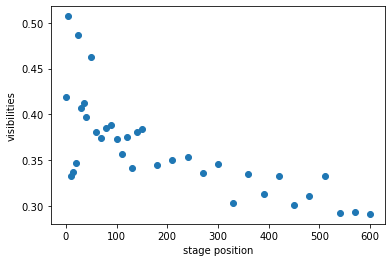

[0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 110.0, 120.0, 130.0, 140.0, 150.0, 180.0, 210.0, 240.0, 270.0, 300.00005, 330.00005, 360.0, 390.0, 420.0, 450.00005, 480.0, 510.0, 540.0, 570.0, 600.0] [0.41889917194349735, 0.5071817731550273, 0.3327375633005662, 0.33772151898734193, 0.3474714518760196, 0.4868004223864835, 0.40738891662506227, 0.4126984126984125, 0.3975903614457832, 0.46225895316804416, 0.3805642633228841, 0.37484197218710497, 0.38495435945860895, 0.3881537492123506, 0.3731629392971247, 0.35645853980839115, 0.3758283370148313, 0.34196547144754325, 0.380907668231612, 0.3837939698492464, 0.3448619886930494, 0.3503014065639652, 0.3536862617733031, 0.33622125958014, 0.3461021505376344, 0.30379746835443033, 0.3353353353353354, 0.31345353675450754, 0.3333333333333333, 0.3013746915756079, 0.3112491373360939, 0.3333333333333333, 0.29257020974049047, 0.2933664420007094, 0.2914734213342846]
Starting scan for power :  10.1


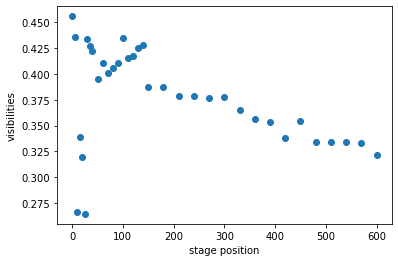

[0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 50.00005, 60.0, 70.0, 80.0, 90.0, 100.0, 110.0, 120.00005, 130.0, 140.0, 150.00005, 180.00005, 210.0, 240.0, 270.0, 300.0, 330.0, 360.0, 390.00005, 420.00005, 450.0, 480.0, 510.0, 540.0, 570.0, 600.0] [0.45586999159428415, 0.4359264497878359, 0.266334295460509, 0.339411520928305, 0.3198746954403063, 0.26451273969004474, 0.4339846062759028, 0.4267062314540059, 0.4226437462951984, 0.39557739557739563, 0.41064287911411873, 0.40088105726872253, 0.40569620253164573, 0.4105004605465152, 0.43470483005366717, 0.41585617447686407, 0.4174528301886792, 0.4247551202137132, 0.42780748663101603, 0.38746081504702207, 0.38737623762376255, 0.37902973395931155, 0.3786650031191517, 0.3769158586174539, 0.3773054079399814, 0.36537237428389574, 0.3563366655917446, 0.3532080362929359, 0.33752898310698903, 0.35421375524701326, 0.333777925975325, 0.3337774816788807, 0.3342228152101401, 0.33355548150616465, 0.32176870748299313]
Starting scan for power :  10.2

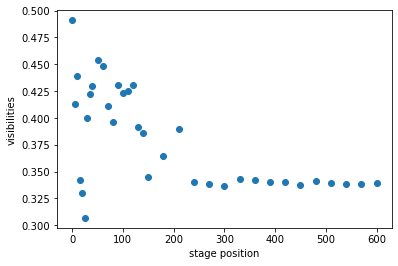

[0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 110.0, 120.0, 130.0, 140.00005, 150.0, 180.0, 210.0, 240.0, 270.0, 300.0, 330.0, 360.00005, 390.0, 420.0, 450.00005, 480.0, 510.0, 540.0, 570.0, 600.0] [0.49099639855942373, 0.4130434782608694, 0.4395218002812939, 0.34210526315789463, 0.3301241449201927, 0.3068905616676319, 0.40006275494195176, 0.4223933649289099, 0.4294205052005942, 0.45399515738498775, 0.44861150873174926, 0.4115176964607079, 0.39647577092511027, 0.43040685224839403, 0.4230882787127251, 0.42529534398888114, 0.4305060584461866, 0.39123809523809494, 0.38562091503267953, 0.3451109285127361, 0.36435958631662674, 0.38977879481311956, 0.3402232327408021, 0.33858267716535434, 0.3369294605809129, 0.34291581108829566, 0.3418451400329489, 0.3407867494824016, 0.34047815333882936, 0.3372189841798501, 0.3413025556471557, 0.3391304347826088, 0.33833333333333326, 0.33803401078390716, 0.3393889347646572]


In [2]:
%load_ext autoreload
%autoreload 2
import heapq
import time

if socket.gethostname() == "ph-photonbec5":
    sys.path.append("D:/Control/PythonPackages/")
    sys.path.append("D:/Control/PiezoController/")

#_________________________________________________________PARAMETERS : CHANGE HERE____________________________________________________________
position_list = np.append(np.append(np.arange(0,40,5),np.arange(40,150,10)),np.arange(150,630,30))
number_of_measurements = 1 # Amount of pics to take at each position of the stage

power_list = power_list = np.append(np.append(np.append(np.append([0],np.arange(11,14,0.25)/1000),np.arange(14,25,1)/1000),np.arange(25,41,3)/1000),np.arange(41,100,10)/1000)
power_list = power_list = np.append(np.append(np.append(np.append([0],np.arange(45,50,0.25)/1000),np.arange(50,60,1)/1000),np.arange(60,90,3)/1000),np.arange(90,150,10)/1000)
power_list = [10/1000,10.1/1000,10.2/1000]
channels = [0, 1]  # Channel A, B
time_range = 13
preSamples = 0
postSamples = 200000
plot_flag = False # If you want to live monitor the data during the acquisition
n_avg = 200 # Number of points over which to perform averaging for Imax and Imin
DC = 5.9
filter_positions = { # Preset the filter position for each power value - Need to be done manually, do it everytime before taking measurements
    45:0,
    57:1,
    75:2,
    # Add more power settings as needed
}
#_________________________________________________________________________________________________________________________________

with comp.Translation_Stage() as stage:
    for power in power_list:
        laser.set(power)
        print('Starting scan for power : ', power*1000)
        stage.set(position_list[0])
        visibilities = []
        time.sleep(5)
        try:
            
            if power*1000 in filter_positions:
                    filter_position = filter_positions[power*1000]
                    filter_wheel.set(filter_position)  # Set the filter position accordingly
                    print(f'Filter position set to: {filter_position+1} for power {power*1000}')
            real_positions =[]
            for k in range(len(position_list)):
                stage.set(position_list[k])
                position = stage.get_position()
                real_positions.append(position)
                
                for k in range(number_of_measurements):
                    a = get_picoscope_data(channels,live_plot=plot_flag,timebase = time_range, preTriggerSamples=preSamples,postTriggerSamples=postSamples)
                    Voltages = a[0]
                    Timing = a[1]
                    chA = np.abs(np.array(a[0][0]))
                    chB = np.abs(np.array(a[0][1]))
                    bg = 2
                    chC = (chA-DC)/(chB-bg)
                    highest_vals = heapq.nlargest(n_avg, chA)
                    lowest_vals = heapq.nsmallest(n_avg, chA)
                    Imax = np.mean(highest_vals)
                    Imin = np.mean(lowest_vals)
                    visibility = (Imax-Imin)/(Imax+Imin)
                    visibilities.append(visibility)
                    save_arrays(Voltages, Timing, position,power*1000)
                    #print('Now at Position : ', position, ' / Visibility : ', visibility)
                time.sleep(1)
            plt.plot(real_positions,visibilities,'o')
            plt.xlabel('stage position')
            plt.ylabel('visibilities')
            plt.show()
            print(real_positions,visibilities)
        except:
            print('An exception occured')
        
    laser.set(0)